In [26]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

# for the count plot and bar plot
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [27]:
df = pd.read_csv("US_Accidents_March23_sampled_500k.csv")
df.describe()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     500000 non-null  str    
 1   Source                 500000 non-null  str    
 2   Severity               500000 non-null  int64  
 3   Start_Time             500000 non-null  str    
 4   End_Time               500000 non-null  str    
 5   Start_Lat              500000 non-null  float64
 6   Start_Lng              500000 non-null  float64
 7   End_Lat                279623 non-null  float64
 8   End_Lng                279623 non-null  float64
 9   Distance(mi)           500000 non-null  float64
 10  Description            499999 non-null  str    
 11  Street                 499309 non-null  str    
 12  City                   499981 non-null  str    
 13  County                 500000 non-null  str    
 14  State                  500000 non-null  str    

In [28]:
# const value 
FILL_NA_VALUE = "NA"
ZERO = 0
# dropping and filling NA
dfClean = df.drop(["ID", "End_Lat", "End_Lng", "Wind_Chill(F)", "Airport_Code"], axis=1)
# fill string null with "NA"
dfClean["Description"] = dfClean["Description"].fillna(FILL_NA_VALUE)
dfClean["Street"] = dfClean["Street"].fillna(FILL_NA_VALUE)
dfClean["City"] = dfClean["City"].fillna(FILL_NA_VALUE)
dfClean["Zipcode"] = dfClean["Zipcode"].fillna(FILL_NA_VALUE)
dfClean["Timezone"] = dfClean["Timezone"].fillna(FILL_NA_VALUE)
dfClean["Weather_Timestamp"] = dfClean["Weather_Timestamp"].fillna(FILL_NA_VALUE)
dfClean["Wind_Direction"] = dfClean["Wind_Direction"].fillna(FILL_NA_VALUE)
dfClean["Weather_Condition"] = dfClean["Weather_Condition"].fillna(FILL_NA_VALUE)
dfClean["Sunrise_Sunset"] = dfClean["Sunrise_Sunset"].fillna(FILL_NA_VALUE)
dfClean["Civil_Twilight"] = dfClean["Civil_Twilight"].fillna(FILL_NA_VALUE)
dfClean["Nautical_Twilight"] = dfClean["Nautical_Twilight"].fillna(FILL_NA_VALUE)
dfClean["Astronomical_Twilight"] = dfClean["Astronomical_Twilight"].fillna(FILL_NA_VALUE)

# fill float NA with mean
dfClean["Temperature(F)"] = dfClean["Temperature(F)"].fillna(dfClean["Temperature(F)"].mean())
dfClean["Humidity(%)"] = dfClean["Humidity(%)"].fillna(dfClean["Humidity(%)"].mean())
dfClean["Pressure(in)"] = dfClean["Pressure(in)"].fillna(dfClean["Pressure(in)"].mean())
dfClean["Visibility(mi)"] = dfClean["Visibility(mi)"].fillna(dfClean["Visibility(mi)"].mean())
dfClean["Wind_Speed(mph)"] = dfClean["Wind_Speed(mph)"].fillna(dfClean["Wind_Speed(mph)"].mean())
dfClean["Precipitation(in)"] = dfClean["Precipitation(in)"].fillna(ZERO)

dfClean.info()


<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Source                 500000 non-null  str    
 1   Severity               500000 non-null  int64  
 2   Start_Time             500000 non-null  str    
 3   End_Time               500000 non-null  str    
 4   Start_Lat              500000 non-null  float64
 5   Start_Lng              500000 non-null  float64
 6   Distance(mi)           500000 non-null  float64
 7   Description            500000 non-null  str    
 8   Street                 500000 non-null  str    
 9   City                   500000 non-null  str    
 10  County                 500000 non-null  str    
 11  State                  500000 non-null  str    
 12  Zipcode                500000 non-null  str    
 13  Country                500000 non-null  str    
 14  Timezone               500000 non-null  str    

In [29]:
# Columns used to identify potential duplicate accidents, this was discovered upon realizing certain wind speed entries where duplicated 
duplicate_columns = [
    "Start_Time",
    "Start_Lat",
    "Start_Lng"
]

# Mark rows that share these values  (True = part of a duplicate group)
is_duplicate = dfClean.duplicated(
    subset=duplicate_columns,
    keep=False
)

# Use the True/False mark determine which rows are duplicates
duplicates = dfClean[is_duplicate].copy()


# Sort so each duplicate group appears together
duplicates = duplicates.sort_values(by=duplicate_columns)

# Drops duplicates in data set, only keeps first occurence of every entry found
dfClean = dfClean.drop_duplicates(subset=duplicate_columns, keep="first")
dfClean.info()

<class 'pandas.DataFrame'>
Index: 497758 entries, 0 to 499999
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Source                 497758 non-null  str    
 1   Severity               497758 non-null  int64  
 2   Start_Time             497758 non-null  str    
 3   End_Time               497758 non-null  str    
 4   Start_Lat              497758 non-null  float64
 5   Start_Lng              497758 non-null  float64
 6   Distance(mi)           497758 non-null  float64
 7   Description            497758 non-null  str    
 8   Street                 497758 non-null  str    
 9   City                   497758 non-null  str    
 10  County                 497758 non-null  str    
 11  State                  497758 non-null  str    
 12  Zipcode                497758 non-null  str    
 13  Country                497758 non-null  str    
 14  Timezone               497758 non-null  str    
 15 

In [30]:

dfClean["Start_Time"] = pd.to_datetime(df["Start_Time"], format="mixed")
dfClean["End_Time"] = pd.to_datetime(df["End_Time"], format = "mixed")

dfClean["Start_Time"]
dfClean["End_Time"]

0        2019-06-12 10:55:58
1        2022-12-04 01:56:53
2        2022-08-20 15:22:45
3        2022-02-21 19:43:23
4        2020-12-04 04:13:09
                 ...        
499995   2021-12-15 07:50:30
499996   2021-12-19 17:40:37
499997   2022-04-13 21:33:44
499998   2020-05-15 17:50:56
499999   2022-04-03 00:49:48
Name: End_Time, Length: 497758, dtype: datetime64[ns]

In [31]:

dfClean["Time_Differ"] = (
    dfClean["End_Time"] - dfClean["Start_Time"]
).dt.total_seconds() / 60

# Extract date components using the .dt accessor
dfClean["Start_Date"] = dfClean["Start_Time"].dt.date
dfClean["End_Date"] = dfClean["End_Time"].dt.date
dfClean["Year"] = dfClean["Start_Time"].dt.year
dfClean["Month"] = dfClean["Start_Time"].dt.month
dfClean["DayOfWeek"] = dfClean["Start_Time"].dt.day_name()
dfClean["Day"] = dfClean["Start_Time"].dt.day
dfClean["Hour"] = dfClean["Start_Time"].dt.hour

# Verify data
dfClean.head()
dfClean.info()

<class 'pandas.DataFrame'>
Index: 497758 entries, 0 to 499999
Data columns (total 49 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   Source                 497758 non-null  str           
 1   Severity               497758 non-null  int64         
 2   Start_Time             497758 non-null  datetime64[ns]
 3   End_Time               497758 non-null  datetime64[ns]
 4   Start_Lat              497758 non-null  float64       
 5   Start_Lng              497758 non-null  float64       
 6   Distance(mi)           497758 non-null  float64       
 7   Description            497758 non-null  str           
 8   Street                 497758 non-null  str           
 9   City                   497758 non-null  str           
 10  County                 497758 non-null  str           
 11  State                  497758 non-null  str           
 12  Zipcode                497758 non-null  str           
 13  

In [32]:
dfDates = dfClean[["Severity","Distance(mi)", "Start_Time", "End_Time", "Time_Differ", "Start_Date", "End_Date", "Year", "Month","DayOfWeek", "Day", "Hour"]]
dfDates.info()

<class 'pandas.DataFrame'>
Index: 497758 entries, 0 to 499999
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Severity      497758 non-null  int64         
 1   Distance(mi)  497758 non-null  float64       
 2   Start_Time    497758 non-null  datetime64[ns]
 3   End_Time      497758 non-null  datetime64[ns]
 4   Time_Differ   497758 non-null  float64       
 5   Start_Date    497758 non-null  object        
 6   End_Date      497758 non-null  object        
 7   Year          497758 non-null  int32         
 8   Month         497758 non-null  int32         
 9   DayOfWeek     497758 non-null  str           
 10  Day           497758 non-null  int32         
 11  Hour          497758 non-null  int32         
dtypes: datetime64[ns](2), float64(2), int32(4), int64(1), object(2), str(1)
memory usage: 41.8+ MB


<function matplotlib.pyplot.show(close=None, block=None)>

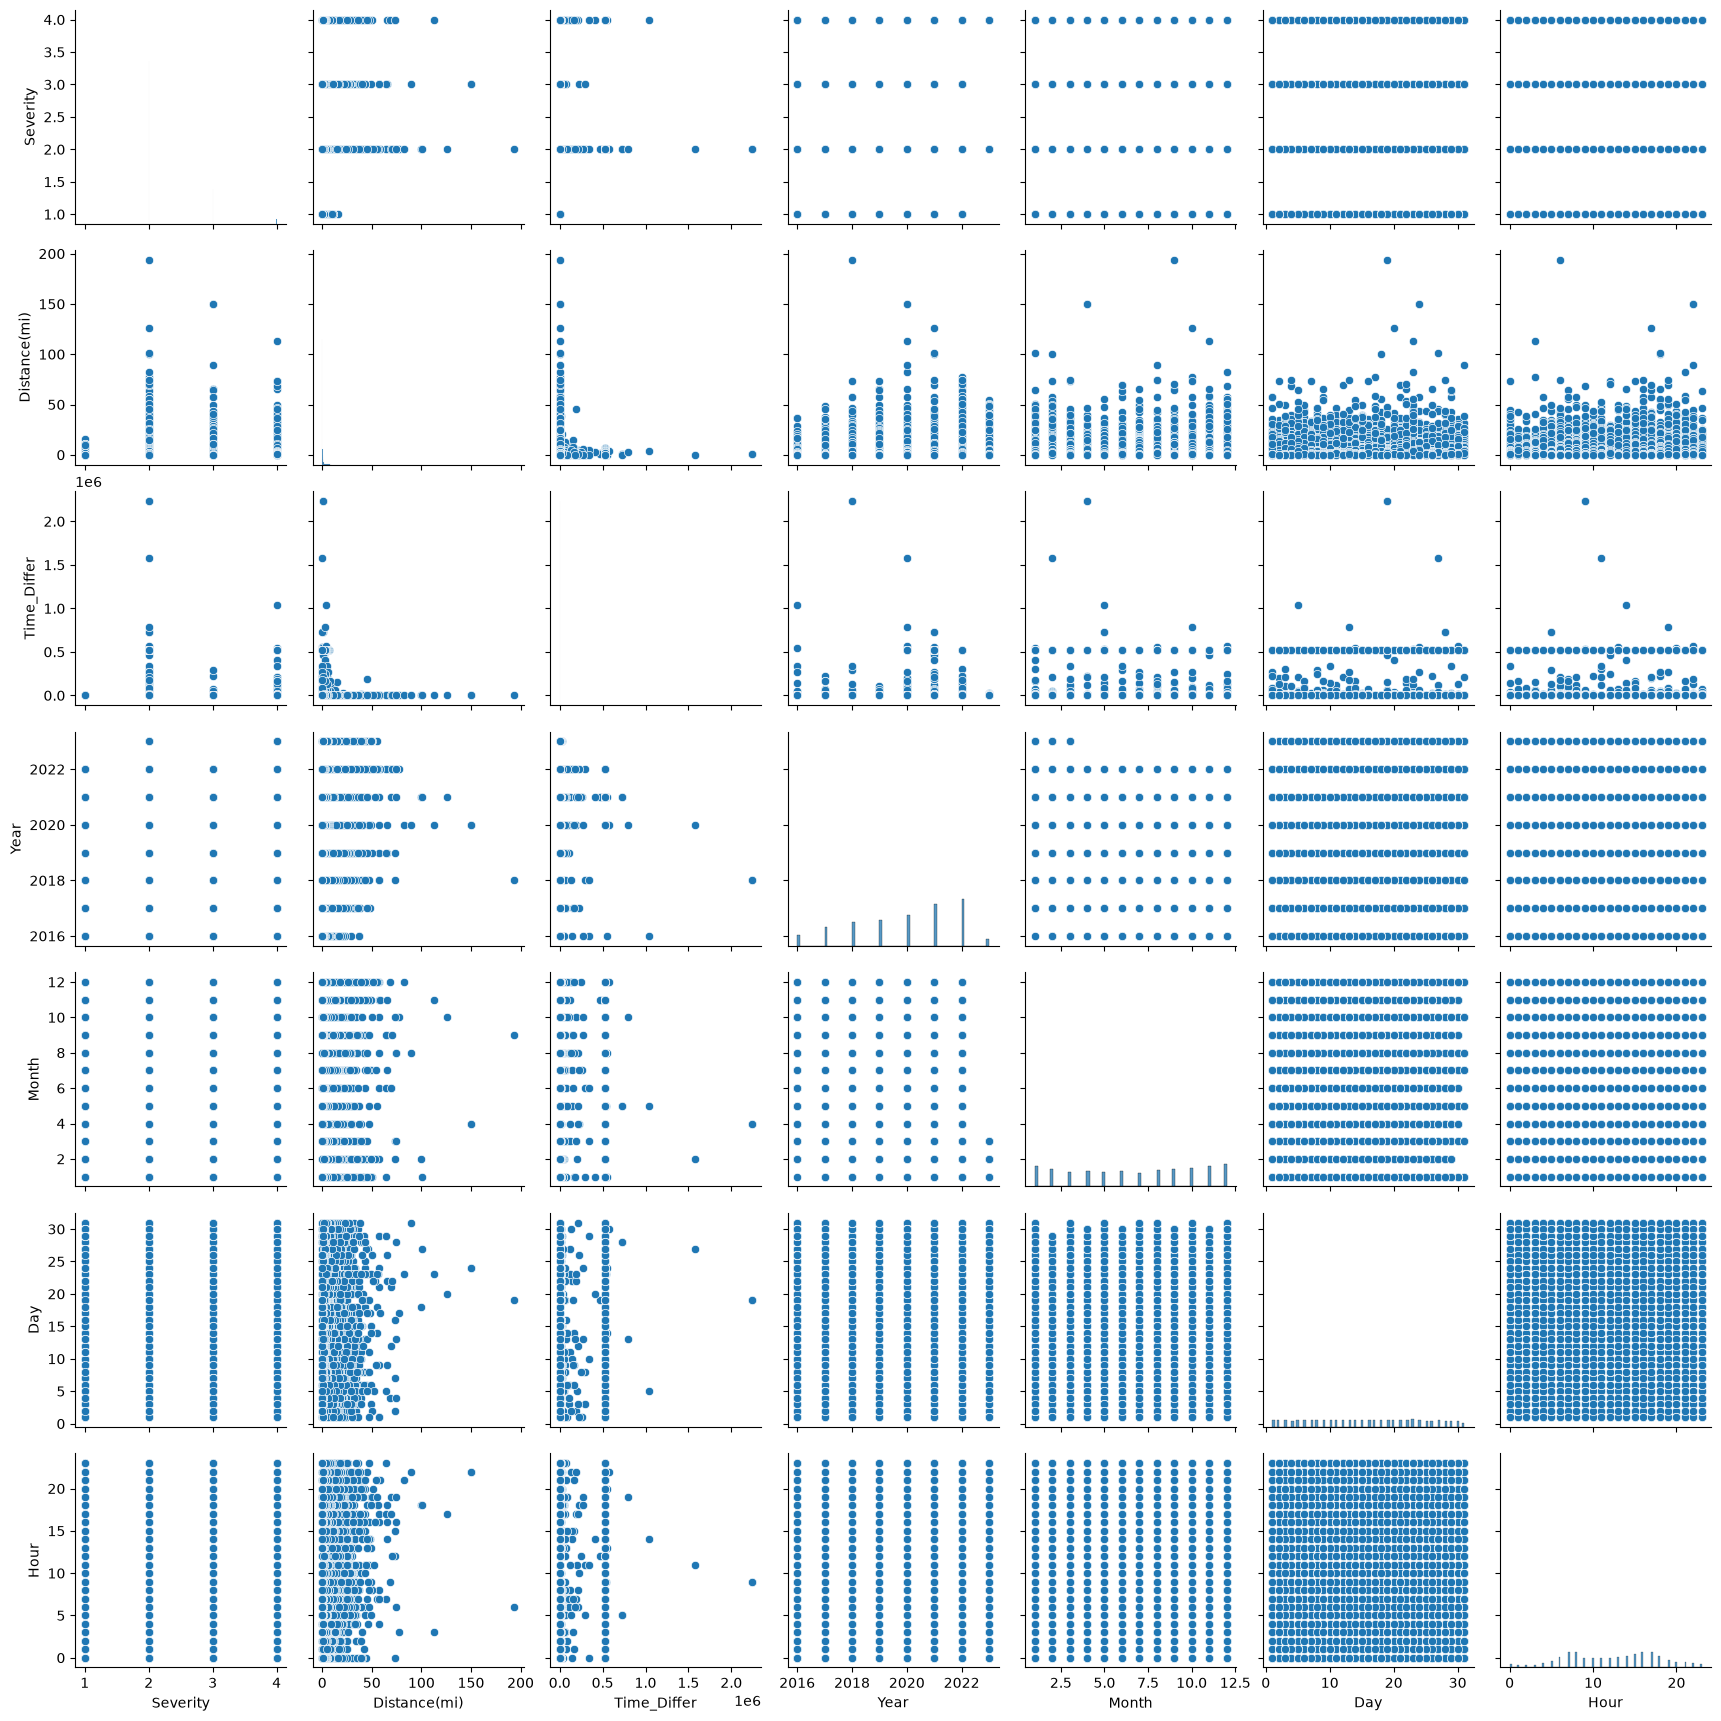

In [33]:
sns.pairplot(dfDates)
plt.show


In [34]:
dfDates["Year"].value_counts().sort_index()

Year
2016     26655
2017     46508
2018     57559
2019     61821
2020     75526
2021    101034
2022    112959
2023     15696
Name: count, dtype: int64

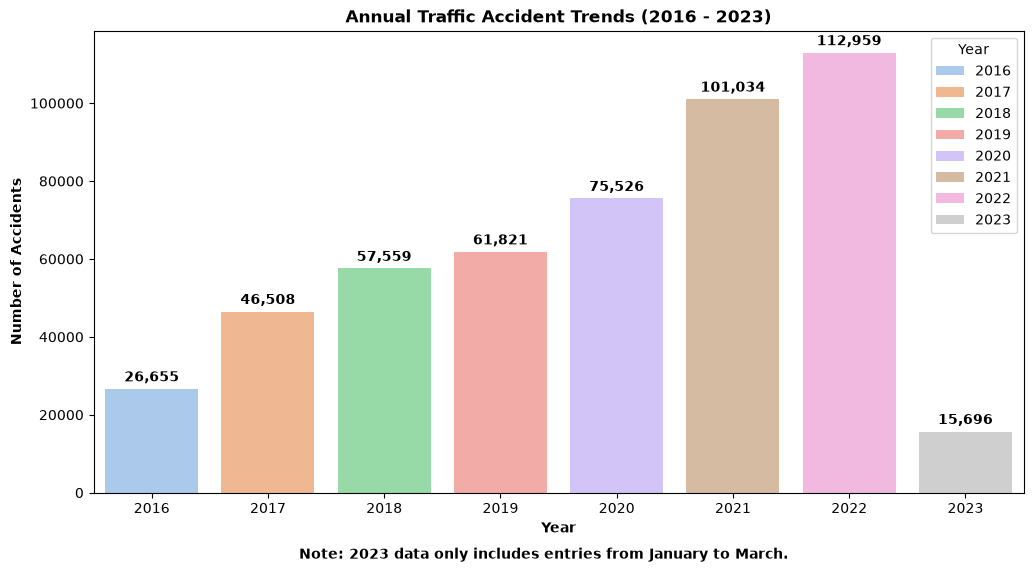

In [50]:
# Count the number of accidents for each year
accidents = dfDates["Year"].value_counts().sort_index()

# Set graph size
plt.figure(figsize=(12, 6))

# Create bar chart with different colors
ax = sns.barplot(
    x = accidents.index,
    y = accidents.values,
    hue = accidents.index,
    palette = "pastel",
)

# Make 2023 gray since it only has 3 months of data
ax.patches[-1].set_color("lightgray")

# Add accident counts above each bar
for bar in ax.containers:
    ax.bar_label(bar, 
                 fmt = "{:,.0f}", 
                 padding = 3,
                 weight = "bold")

# Add title and labels
plt.title("Annual Traffic Accident Trends (2016 - 2023)", weight = "bold")
plt.xlabel("Year", weight = "bold")
plt.ylabel("Number of Accidents", weight = "bold")

# Add note about 2023
plt.figtext(
    0.5, 0,
    "Note: 2023 data only includes entries from January to March.",
    ha="center",
    weight = "bold"
)


plt.show()

In [36]:
dfClean["Hour"]

0         10
1         23
2         13
3         17
4          1
          ..
499995     7
499996    16
499997    19
499998    17
499999    23
Name: Hour, Length: 497758, dtype: int32

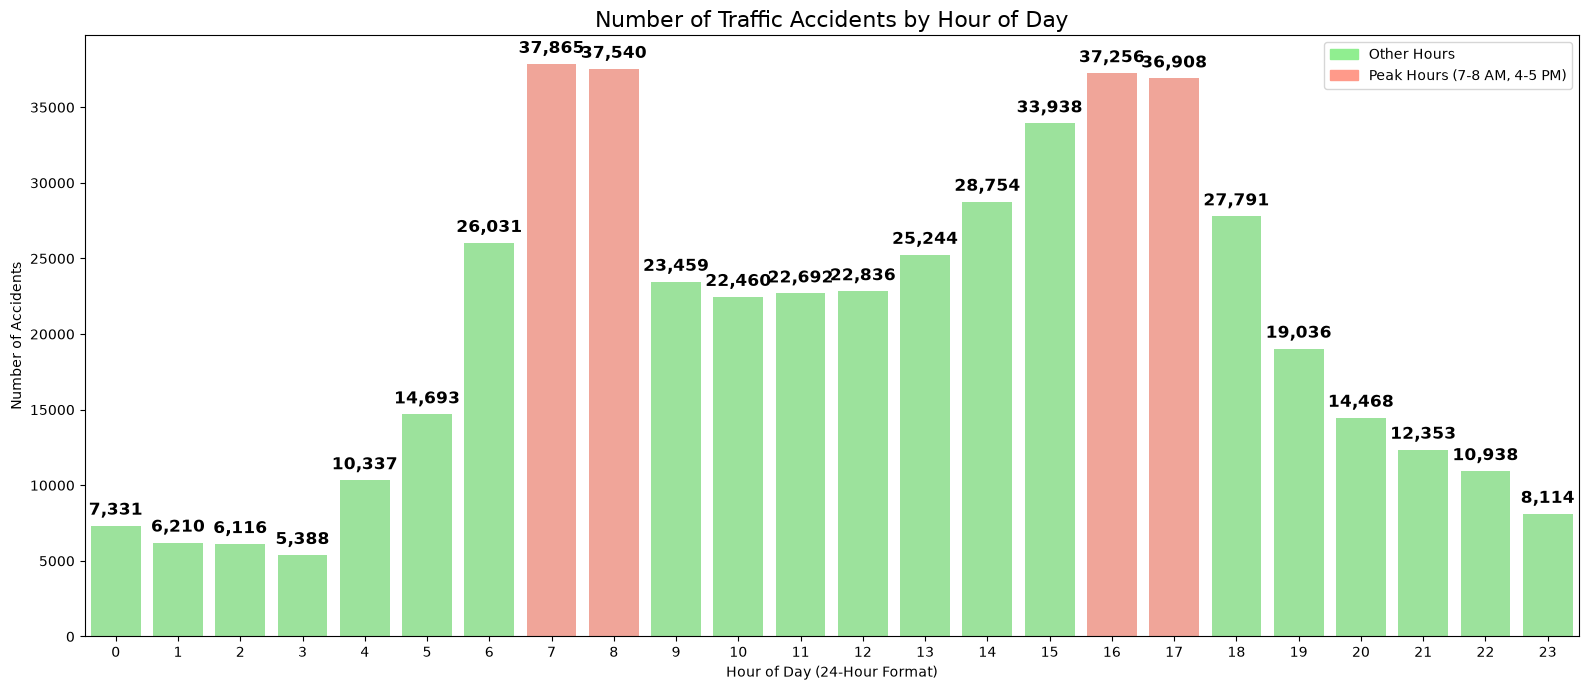

In [ ]:
from matplotlib.patches import Patch

# Count accidents for each hour (0-23)
hour_of_accident = dfDates["Hour"].value_counts().reindex(range(24), fill_value=0)

# Set graph size
plt.figure(figsize=(16, 7))

# Set colors for each hour
colors = ["lightgreen"] * 24

# Highlight morning rush hours (7 - 8AM)
colors[7] = "#ff9a8a"
colors[8] = "#ff9a8a"

# Highlight afternoon rush hours (4 - 5PM)
colors[16] = "#ff9a8a"
colors[17] = "#ff9a8a"

# Create bar chart
ax = sns.barplot(
    x=hour_of_accident.index,
    y=hour_of_accident.values,
    hue=hour_of_accident.index,
    palette=colors,
    legend=False
)

# Add accident counts above each bar
for bar in ax.containers:
    ax.bar_label(
        bar,
        fmt="{:,.0f}",
        padding=5,
        fontsize=10,
        weight="bold"
    )

# Add title and labels
plt.title("Number of Traffic Accidents by Hour of Day", fontsize=16)
plt.xlabel("Hour of Day (24-Hour Format)")
plt.ylabel("Number of Accidents")

# Add legend
plt.legend(handles=[
    Patch(color="lightgreen", label="Other Hours"),
    Patch(color="#ff9a8a", label="Peak Hours (7-8 AM, 4-5 PM)")
])


# Improve layout
plt.tight_layout()
plt.show()

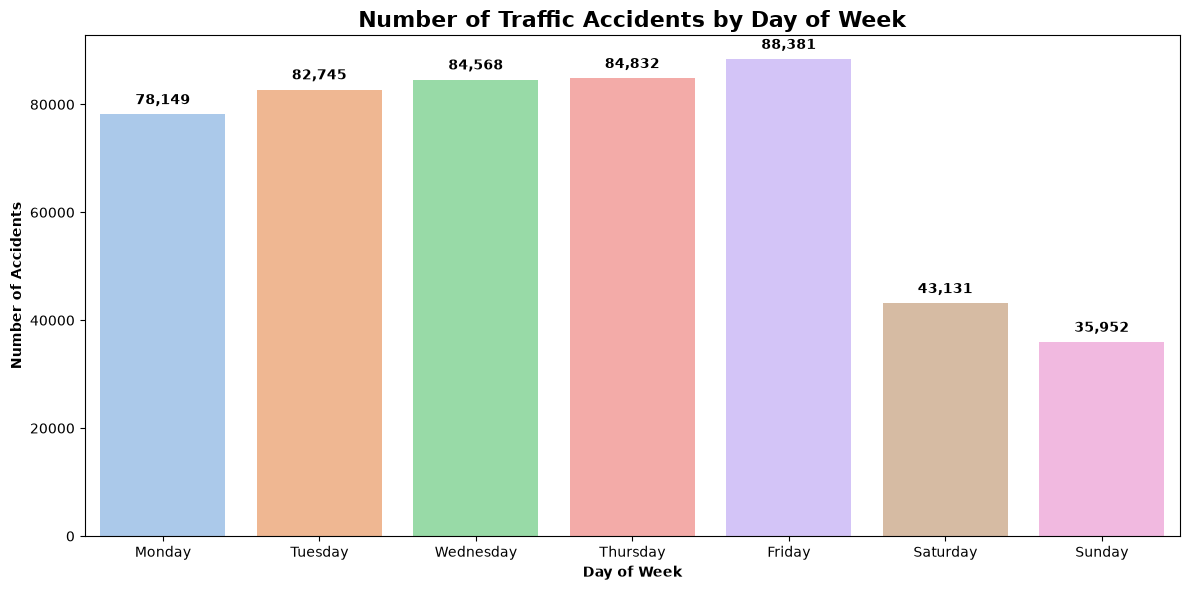

In [45]:
# Count accidents for each day of the week
days = ["Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"]

day_of_accident = dfDates["DayOfWeek"].value_counts().reindex(days)

# Set graph size
plt.figure(figsize=(12, 6))

# Create bar chart
ax = sns.barplot(
    x=day_of_accident.index,
    y=day_of_accident.values,
    hue=day_of_accident.index,
    palette="pastel",
)

# Add accident counts above each bar
for bar in ax.containers:
    ax.bar_label(bar, 
                 fmt="{:,.0f}",
                 padding=5, 
                 weight = "bold")

# Add title and labels
plt.title("Number of Traffic Accidents by Day of Week", fontsize=16, weight = "bold")
plt.xlabel("Day of Week", weight = "bold")
plt.ylabel("Number of Accidents", weight = "bold")

plt.tight_layout()
plt.show()

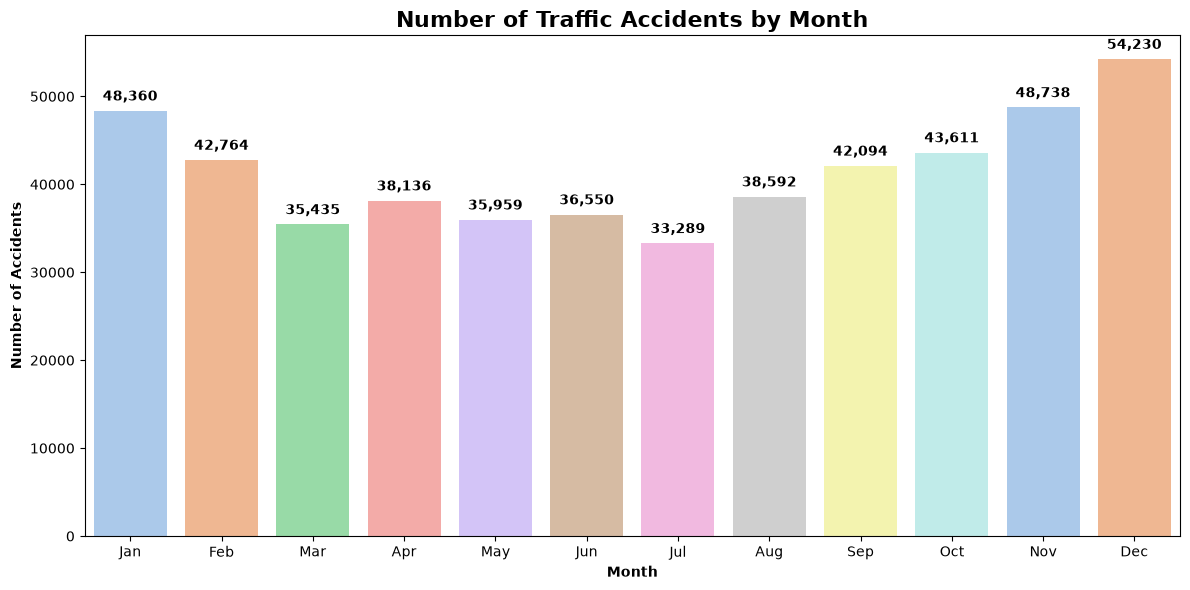

In [44]:
# Count accidents for each month
month_of_accident = dfDates["Month"].value_counts().sort_index()

# Month names
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Set graph size
plt.figure(figsize=(12, 6))

# Create bar chart
ax = sns.barplot(
    x = months,
    y = month_of_accident.reindex(range(1, 13), fill_value=0).values,
    hue = months,
    palette = "pastel",
)

# Add accident counts
for bar in ax.containers:
    ax.bar_label(bar, 
                 fmt="{:,.0f}", 
                 padding=5, 
                 weight = "bold")

# Add title and labels
plt.title("Number of Traffic Accidents by Month", fontsize=16, weight = "bold")
plt.xlabel("Month", weight = "bold")
plt.ylabel("Number of Accidents", weight = "bold")

plt.tight_layout()
plt.show()

In [40]:
corr = dfDates.corr(numeric_only=True)
corr

,Severity,Distance(mi),Time_Differ,Year,Month,Day,Hour
Severity,1.000000,0.032491,0.001012,-0.246987,-0.012226,0.001193,0.014996
Distance(mi),0.032491,1.000000,0.013538,0.142898,0.003595,0.002876,-0.001016
Time_Differ,0.001012,0.013538,1.000000,0.010566,0.000027,0.002292,-0.000494
Year,-0.246987,0.142898,0.010566,1.000000,-0.163560,-0.007055,0.025649
Month,-0.012226,0.003595,0.000027,-0.163560,1.000000,-0.007803,0.017686
Day,0.001193,0.002876,0.002292,-0.007055,-0.007803,1.000000,0.002644
Hour,0.014996,-0.001016,-0.000494,0.025649,0.017686,0.002644,1.000000


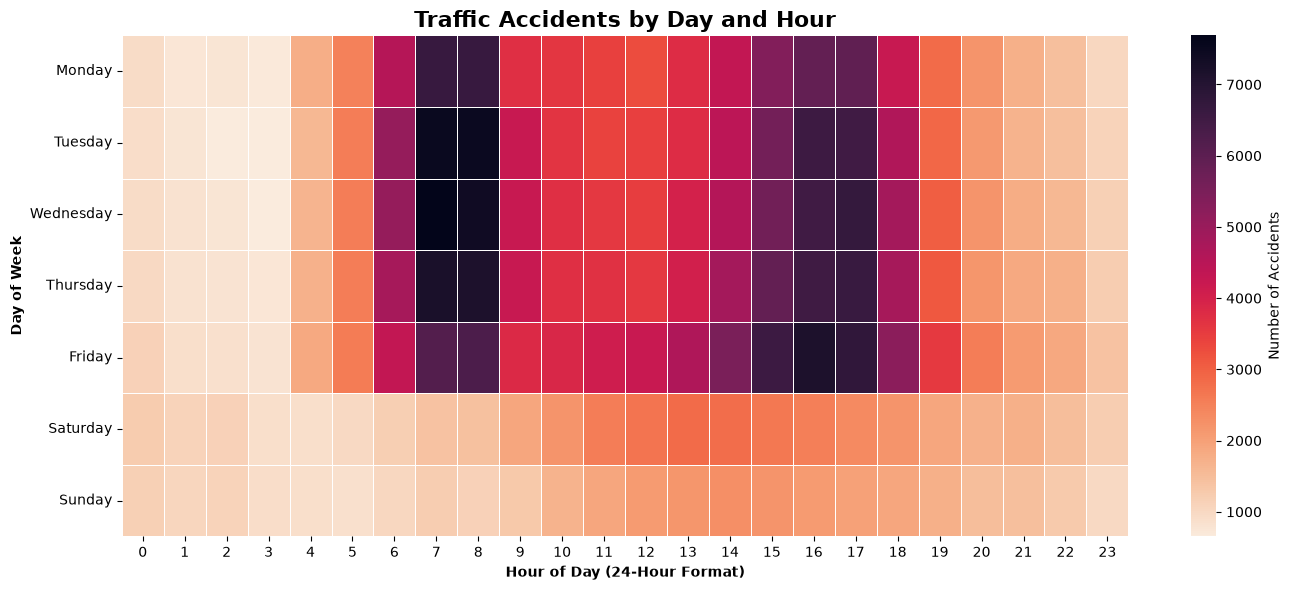

In [46]:
# Count accidents by day and hour
group_day = dfDates.groupby(["DayOfWeek", "Hour"]).size().unstack(fill_value=0)

# Order days correctly
days = ["Monday", "Tuesday", "Wednesday","Thursday", "Friday", "Saturday", "Sunday"]

group_day = group_day.reindex(days)

# Set graph size
plt.figure(figsize=(14, 6))

# Create heatmap
sns.heatmap(
    group_day,
    cmap="rocket_r",
    linewidths=0.5,
    cbar_kws={"label": "Number of Accidents"}
)

# Add title and labels
plt.title("Traffic Accidents by Day and Hour", 
          fontsize=16, 
          fontweight="bold")
plt.xlabel("Hour of Day (24-Hour Format)",
           weight = "bold")
plt.ylabel("Day of Week",
           weight = "bold")

plt.tight_layout()
plt.show()